In [10]:
!pip install -q PyWavelets xgboost

In [11]:
import os, time, json, warnings, joblib, urllib.request
from functools import partial
import numpy as np, scipy.io as sio, pywt
import pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import kurtosis, skew
from scipy.signal import decimate, stft
from joblib import Parallel, delayed
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")

DATA_DIR = "cwru"
OUT_DIR = "results"
FS, WIN, STEP = 12000, 2048, 1024
WAVELET, LEVEL, DENOISE, SEED = "db4", 5, False, 42
NORMAL_FS = 48000      # normal files (97-100) are 48 kHz -> decimated by 4 to 12 kHz
TUNE = True            # load-grouped CV hyper-parameter tuning (slow). Set False for a quick run.
TEST_LOAD = 3

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

FILES = {
    "Normal":   [97, 98, 99, 100],
    "IR_007":   [105, 106, 107, 108], "IR_014":   [169, 170, 171, 172], "IR_021":   [209, 210, 211, 212],
    "Ball_007": [118, 119, 120, 121], "Ball_014": [185, 186, 187, 188], "Ball_021": [222, 223, 224, 225],
    "OR_007":   [130, 131, 132, 133], "OR_014":   [197, 198, 199, 200], "OR_021":   [234, 235, 236, 237],
}
CLASSES = list(FILES.keys())

In [12]:
# ---- Download CWRU data (skips files that already exist) ----
nums = [n for v in FILES.values() for n in v]
patterns = [
    "https://engineering.case.edu/sites/default/files/{n}.mat",
    "https://csegroups.case.edu/sites/default/files/bearingdatacenter/files/Datafiles/{n}.mat",
    "http://csegroups.case.edu/sites/default/files/bearingdatacenter/files/Datafiles/{n}.mat",
]
missing = []
for n in nums:
    dst = f"{DATA_DIR}/{n}.mat"
    if os.path.exists(dst) and os.path.getsize(dst) > 10000:
        continue
    for p in patterns:
        try:
            urllib.request.urlretrieve(p.format(n=n), dst)
            if os.path.getsize(dst) > 10000:
                break
        except Exception:
            pass
    else:
        missing.append(n)
print("missing:", missing)
if missing:
    print("Download these manually from the CWRU Bearing Data Center and upload to the 'cwru/' folder.")

missing: []


In [15]:
import os, time, urllib.request
import scipy.io as sio

nums = [n for v in FILES.values() for n in v]
patterns = [
    "https://engineering.case.edu/sites/default/files/{n}.mat",
    "https://csegroups.case.edu/sites/default/files/bearingdatacenter/files/Datafiles/{n}.mat",
    "http://csegroups.case.edu/sites/default/files/bearingdatacenter/files/Datafiles/{n}.mat",
]

def is_valid(path):
    try:
        m = sio.loadmat(path)
        return any(k.endswith("_DE_time") for k in m)
    except Exception:
        return False

def fetch(url):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=60) as r:
        data = r.read()
        cl = r.headers.get("Content-Length")
        if cl and len(data) != int(cl):
            raise IOError("truncated download")
        return data

bad = [n for n in nums if not (os.path.exists(f"{DATA_DIR}/{n}.mat") and is_valid(f"{DATA_DIR}/{n}.mat"))]
print("bad files:", bad)

for n in bad:
    dst = f"{DATA_DIR}/{n}.mat"
    if os.path.exists(dst):
        print(f"  {n}.mat size on disk: {os.path.getsize(dst)} bytes -> deleting")
        os.remove(dst)
    ok = False
    for p in patterns:
        for attempt in range(3):
            try:
                open(dst, "wb").write(fetch(p.format(n=n)))
                if is_valid(dst):
                    ok = True
                    break
                os.remove(dst)
            except Exception as e:
                if os.path.exists(dst): os.remove(dst)
                time.sleep(2)
        if ok: break
    print(f"  {n}.mat ->", "OK" if ok else "FAILED")

still = [n for n in nums if not (os.path.exists(f"{DATA_DIR}/{n}.mat") and is_valid(f"{DATA_DIR}/{n}.mat"))]
print("still bad:", still)

bad files: [99]
  99.mat size on disk: 4256338 bytes -> deleting
  99.mat -> OK
still bad: []


In [13]:
# ---- Loading, windowing, features ----
def load_de(num):
    m = sio.loadmat(f"{DATA_DIR}/{num}.mat")
    key = [k for k in m if k.endswith("_DE_time")][0]
    return m[key].ravel().astype(np.float64)

def windows(sig):
    n = (len(sig) - WIN) // STEP + 1
    return np.stack([sig[i * STEP:i * STEP + WIN] for i in range(n)])

def load_all_windows():
    W, y, load = [], [], []
    for ci, name in enumerate(CLASSES):
        for ld, num in enumerate(FILES[name]):
            sig = load_de(num)
            if name == "Normal" and NORMAL_FS == 48000:
                sig = decimate(sig, 4)
            w = windows(sig)
            W.append(w); y += [ci] * len(w); load += [ld] * len(w)
    return np.vstack(W), np.array(y), np.array(load)

def denoise(x, wavelet=WAVELET, level=LEVEL):
    c = pywt.wavedec(x, wavelet, level=level)
    sigma = np.median(np.abs(c[-1])) / 0.6745
    thr = sigma * np.sqrt(2 * np.log(len(x)))
    c[1:] = [pywt.threshold(d, thr, mode="soft") for d in c[1:]]
    return pywt.waverec(c, wavelet)[:len(x)]

def wavelet_features(x, wavelet=WAVELET):
    if DENOISE:
        x = denoise(x, wavelet)
    c = pywt.wavedec(x, wavelet, level=LEVEL)          # [cA5, cD5, ..., cD1]
    e = np.array([np.sum(ci ** 2) for ci in c]); rel = e / e.sum()
    f = list(rel)
    for ci in c:
        f += [np.mean(np.abs(ci)), np.std(ci), kurtosis(ci), skew(ci), np.max(np.abs(ci))]
    p = rel + 1e-12
    f.append(-np.sum(p * np.log2(p)))                  # wavelet entropy
    return np.array(f)                                 # 6 + 30 + 1 = 37

def time_features(x):
    rms = np.sqrt(np.mean(x ** 2)); pk = np.max(np.abs(x))
    return np.array([x.mean(), x.std(), rms, pk, kurtosis(x), skew(x),
                     pk / rms, pk / np.mean(np.abs(x))])   # 8

def _chunk(fn, chunk):
    return np.array([fn(w) for w in chunk])

def featurize(fn, W, n_chunks=64):
    chunks = np.array_split(W, n_chunks)
    out = Parallel(n_jobs=-1)(delayed(_chunk)(fn, c) for c in chunks if len(c))
    return np.vstack(out)

def make_models(params=None):
    p = params or {}
    rf = {"n_estimators": 300, "random_state": SEED, "n_jobs": -1};  rf.update(p.get("RandomForest", {}))
    xg = {"n_estimators": 300, "max_depth": 6, "learning_rate": 0.1, "subsample": 0.8,
          "colsample_bytree": 0.8, "random_state": SEED, "n_jobs": -1};  xg.update(p.get("XGBoost", {}))
    sv = {"kernel": "rbf", "C": 10, "gamma": "scale"};  sv.update(p.get("SVM-RBF", {}))
    return {
        "RandomForest": RandomForestClassifier(**rf),
        "XGBoost": XGBClassifier(**xg),
        "SVM-RBF": make_pipeline(StandardScaler(), SVC(**sv)),
    }

def tune_models(X, y, load, test_load):
    """Load-grouped CV on the TRAINING loads only (never sees the test load)."""
    tr = load != test_load
    gkf = GroupKFold(n_splits=len(np.unique(load[tr])))
    grids = {
        "RandomForest": {"max_depth": [None, 20], "min_samples_leaf": [1, 3]},
        "XGBoost": {"max_depth": [4, 6], "learning_rate": [0.05, 0.1]},
        "SVM-RBF": {"svc__C": [1, 10, 100], "svc__gamma": ["scale", 0.01]},
    }
    best = {}
    for name, m in make_models().items():
        gs = GridSearchCV(m, grids[name], cv=gkf, scoring="f1_macro", n_jobs=1)
        gs.fit(X[tr], y[tr], groups=load[tr])
        bp = gs.best_params_
        if name == "SVM-RBF":
            bp = {k.replace("svc__", ""): v for k, v in bp.items()}
        best[name] = bp
        print(f"  tuned {name:12s}: {bp} (grouped-CV macroF1 {gs.best_score_:.4f})")
    return best

In [16]:
t_start = time.time()
print("Loading and windowing ...")
W, y, load = load_all_windows()
print("windows:", W.shape)

print("Extracting features (db4 wavelet + time-domain) ...")
Xw = featurize(wavelet_features, W)
Xt = featurize(time_features, W)
print("Xw", Xw.shape, "Xt", Xt.shape)
np.savez_compressed(f"{OUT_DIR}/features.npz", Xw=Xw, Xt=Xt, y=y, load=load)

tr, te = load != TEST_LOAD, load == TEST_LOAD
fill = {"total_windows": int(len(y)), "train_windows": int(tr.sum()), "test_windows": int(te.sum())}
pd.DataFrame(
    {"Item": ["Classes", "Window length / step", "Total windows",
              "Training windows (0,1,2 hp)", "Test windows (3 hp)"],
     "Value": [len(CLASSES), f"{WIN} / {STEP} samples", len(y), int(tr.sum()), int(te.sum())]}
).to_csv(f"{OUT_DIR}/table2_dataset_sizes.csv", index=False)
print("\nTable 2 :", fill["total_windows"], fill["train_windows"], fill["test_windows"])
print("Windows per class:", {c: int(n) for c, n in zip(CLASSES, np.bincount(y))})

Loading and windowing ...
windows: (4643, 2048)
Extracting features (db4 wavelet + time-domain) ...
Xw (4643, 37) Xt (4643, 8)

Table 2 : 4643 3465 1178
Windows per class: {'Normal': 409, 'IR_007': 472, 'IR_014': 468, 'IR_021': 470, 'Ball_007': 469, 'Ball_014': 471, 'Ball_021': 471, 'OR_007': 471, 'OR_014': 470, 'OR_021': 472}


In [17]:
params = None
if TUNE:
    print("Tuning (load-grouped CV on 0,1,2 hp) ...")
    params = tune_models(Xw, y, load, TEST_LOAD)
    json.dump(params, open(f"{OUT_DIR}/best_params.json", "w"), default=str)

Tuning (load-grouped CV on 0,1,2 hp) ...
  tuned RandomForest: {'max_depth': None, 'min_samples_leaf': 3} (grouped-CV macroF1 0.9676)
  tuned XGBoost     : {'learning_rate': 0.05, 'max_depth': 4} (grouped-CV macroF1 0.9453)
  tuned SVM-RBF     : {'C': 1, 'gamma': 0.01} (grouped-CV macroF1 0.8843)


In [18]:
print("=== Table 3: cross-load test (3 hp) ===")
res, rows = {}, []
for name, m in make_models(params).items():
    t0 = time.time(); m.fit(Xw[tr], y[tr]); p = m.predict(Xw[te])
    acc, f1 = accuracy_score(y[te], p), f1_score(y[te], p, average="macro")
    res[name] = (acc, f1, p, m)
    rows.append([name, "Wavelet (37)", acc, f1])
    print(f"{name:13s} acc {acc:.4f} macroF1 {f1:.4f} ({time.time() - t0:.1f}s)")

rf_t = make_models(params)["RandomForest"].fit(Xt[tr], y[tr])
pt = rf_t.predict(Xt[te])
acc_t, f1_t = accuracy_score(y[te], pt), f1_score(y[te], pt, average="macro")
rows.append(["RandomForest", "Time-domain only (8)", acc_t, f1_t])
print(f"RF time-domain acc {acc_t:.4f} macroF1 {f1_t:.4f}")

pd.DataFrame(rows, columns=["Classifier", "Features", "Test accuracy", "Macro F1"]
             ).round(4).to_csv(f"{OUT_DIR}/table3_test_accuracy.csv", index=False)
best = max(res, key=lambda k: res[k][0])
fill["best_model"], fill["best_acc"], fill["best_f1"] = best, res[best][0], res[best][1]
fill["time_only_acc"] = acc_t

=== Table 3: cross-load test (3 hp) ===
RandomForest  acc 0.9907 macroF1 0.9906 (3.4s)
XGBoost       acc 0.9788 macroF1 0.9787 (2.6s)
SVM-RBF       acc 0.9907 macroF1 0.9907 (0.2s)
RF time-domain acc 0.9669 macroF1 0.9672


In [19]:
print("=== Leave-one-load-out (mean +/- std over 4 loads) ===")
lolo_rows = []
for name in make_models():
    accs = []
    for L in range(4):
        a, b = load != L, load == L
        m = make_models(params)[name].fit(Xw[a], y[a])
        accs.append(accuracy_score(y[b], m.predict(Xw[b])))
    lolo_rows.append([name] + list(np.round(accs, 4)) + [np.mean(accs), np.std(accs)])
    print(f"{name:13s} {np.round(accs, 4)} mean {np.mean(accs):.4f} std {np.std(accs):.4f}")
pd.DataFrame(lolo_rows, columns=["Model", "0hp", "1hp", "2hp", "3hp", "Mean", "Std"]
             ).round(4).to_csv(f"{OUT_DIR}/table_lolo.csv", index=False)
fill["lolo"] = {r[0]: (r[-2], r[-1]) for r in lolo_rows}

print("\n=== Random (leaky) split vs cross-load, Random Forest ===")
Xa, Xb, ya, yb = train_test_split(Xw, y, test_size=0.3, stratify=y, random_state=SEED)
rand_acc = accuracy_score(yb, make_models(params)["RandomForest"].fit(Xa, ya).predict(Xb))
fill["random_split_acc"] = rand_acc
print(f"random 70/30 split acc {rand_acc:.4f} vs cross-load {res['RandomForest'][0]:.4f}")

=== Leave-one-load-out (mean +/- std over 4 loads) ===
RandomForest  [0.9355 0.9915 0.9991 0.9907] mean 0.9792 std 0.0255
XGBoost       [0.8763 0.9881 0.994  0.9788] mean 0.9593 std 0.0482
SVM-RBF       [0.8486 0.9243 0.9974 0.9907] mean 0.9402 std 0.0602

=== Random (leaky) split vs cross-load, Random Forest ===
random 70/30 split acc 0.9943 vs cross-load 0.9907


=== Per-class report (RandomForest) ===
              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000       117
      IR_007      1.000     1.000     1.000       119
      IR_014      1.000     1.000     1.000       117
      IR_021      1.000     1.000     1.000       118
    Ball_007      1.000     0.991     0.996       117
    Ball_014      0.952     1.000     0.975       118
    Ball_021      0.959     1.000     0.979       118
      OR_007      1.000     1.000     1.000       118
      OR_014      1.000     0.915     0.956       118
      OR_021      1.000     1.000     1.000       118

    accuracy                          0.991      1178
   macro avg      0.991     0.991     0.991      1178
weighted avg      0.991     0.991     0.991      1178



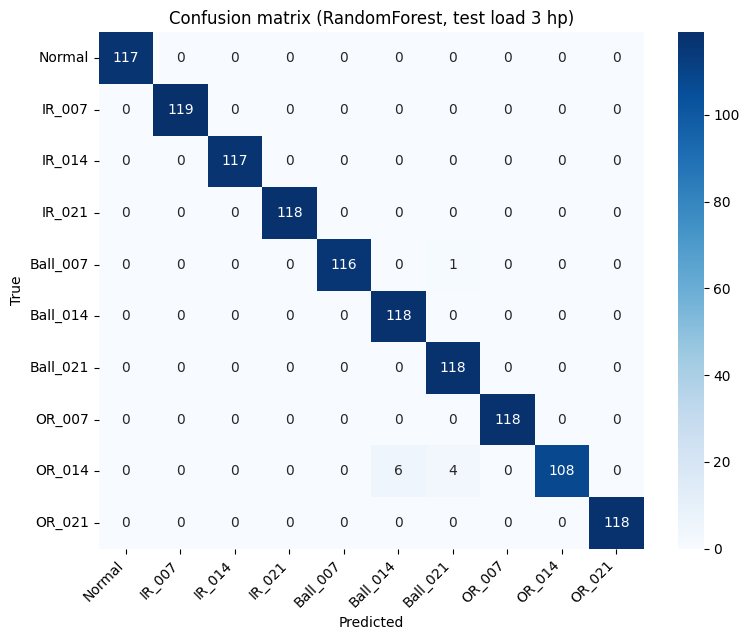

In [20]:
print(f"=== Per-class report ({best}) ===")
p_best = res[best][2]
print(classification_report(y[te], p_best, target_names=CLASSES, digits=3))
f1c = f1_score(y[te], p_best, average=None)
order = np.argsort(f1c)[::-1]
strong = [f"{CLASSES[i]} ({f1c[i]:.3f})" for i in order[:3]]
weak = [f"{CLASSES[i]} ({f1c[i]:.3f})" for i in order[::-1][:3]]
pd.DataFrame({"Strongest classes (F1)": strong, "Weakest classes (F1)": weak}
             ).to_csv(f"{OUT_DIR}/table4_per_class.csv", index=False)
pd.DataFrame(classification_report(y[te], p_best, target_names=CLASSES, digits=3,
                                   output_dict=True)).T.round(3
             ).to_csv(f"{OUT_DIR}/per_class_full_report.csv")
fill["strong"], fill["weak"] = strong, weak

plt.figure(figsize=(8, 6.5))
sns.heatmap(confusion_matrix(y[te], p_best), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Confusion matrix ({best}, test load {TEST_LOAD} hp)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig3_confusion_matrix.png", dpi=300)
plt.show()

In [21]:
print("=== Table 5: ablation (Random Forest, test 3 hp) ===")
rf = lambda: make_models(params)["RandomForest"]
abl = []
for wv in ["haar", "db2", "db4", "db8"]:
    Xv = featurize(partial(wavelet_features, wavelet=wv), W)
    a1 = accuracy_score(y[te], rf().fit(Xv[tr], y[tr]).predict(Xv[te]))
    Xc = np.hstack([Xv, Xt])
    a2 = accuracy_score(y[te], rf().fit(Xc[tr], y[tr]).predict(Xc[te]))
    abl.append([wv, a1, a2]); print(f"{wv:5s} wavelet {a1:.4f} | time+wavelet {a2:.4f}")
pd.DataFrame(abl, columns=["Mother wavelet", "Wavelet features only", "Time + wavelet"]
             ).round(4).to_csv(f"{OUT_DIR}/table5_ablation.csv", index=False)
fill["ablation"] = abl

=== Table 5: ablation (Random Forest, test 3 hp) ===
haar  wavelet 0.9694 | time+wavelet 0.9533
db2   wavelet 0.9839 | time+wavelet 0.9830
db4   wavelet 0.9907 | time+wavelet 0.9856
db8   wavelet 0.9983 | time+wavelet 0.9915


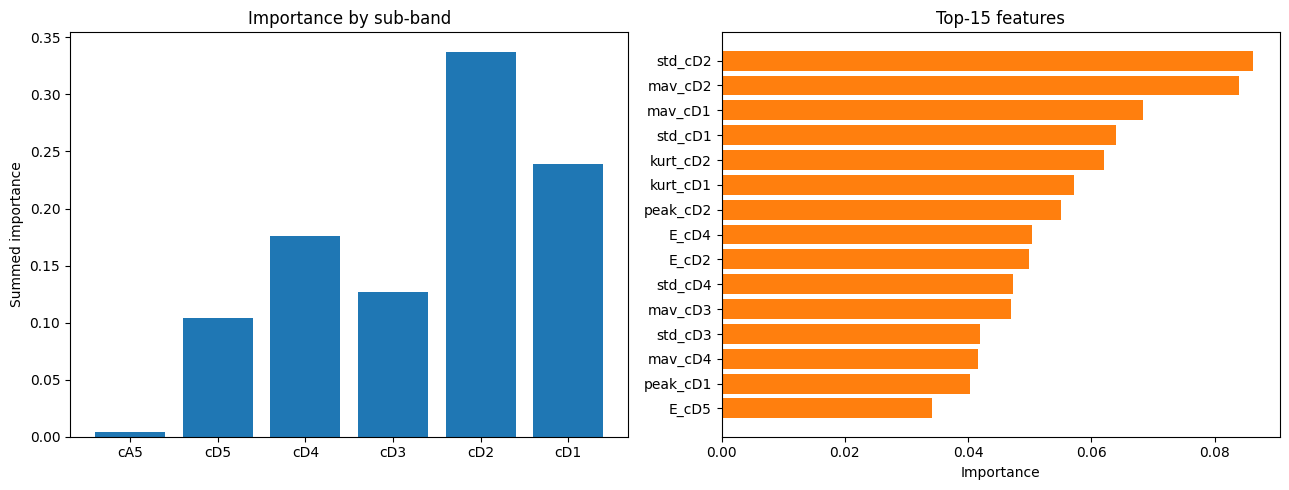

Band importance: {'cA5': 0.004, 'cD5': 0.104, 'cD4': 0.176, 'cD3': 0.127, 'cD2': 0.338, 'cD1': 0.239}
Top-5 features : ['std_cD2', 'mav_cD2', 'mav_cD1', 'std_cD1', 'kurt_cD2']


In [22]:
bands = ["cA5", "cD5", "cD4", "cD3", "cD2", "cD1"]
names = (["E_" + b for b in bands]
         + [s + "_" + b for b in bands for s in ["mav", "std", "kurt", "skew", "peak"]]
         + ["entropy"])
rf_m = make_models(params)["RandomForest"].fit(Xw[tr], y[tr])
imp = rf_m.feature_importances_
band_imp = {b: float(sum(imp[i] for i, n in enumerate(names) if n.endswith("_" + b))) for b in bands}
fill["band_importance"] = band_imp
fill["entropy_importance"] = float(imp[-1])
top = np.argsort(imp)[::-1][:15]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].bar(band_imp.keys(), band_imp.values(), color="tab:blue")
ax[0].set_ylabel("Summed importance"); ax[0].set_title("Importance by sub-band")
ax[1].barh([names[i] for i in top][::-1], imp[top][::-1], color="tab:orange")
ax[1].set_xlabel("Importance"); ax[1].set_title("Top-15 features")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig4_feature_importance.png", dpi=300); plt.show()

joblib.dump(rf_m, f"{OUT_DIR}/bearing_rf.pkl")
print("Band importance:", {k: round(v, 3) for k, v in band_imp.items()})
print("Top-5 features :", [names[i] for i in top[:5]])

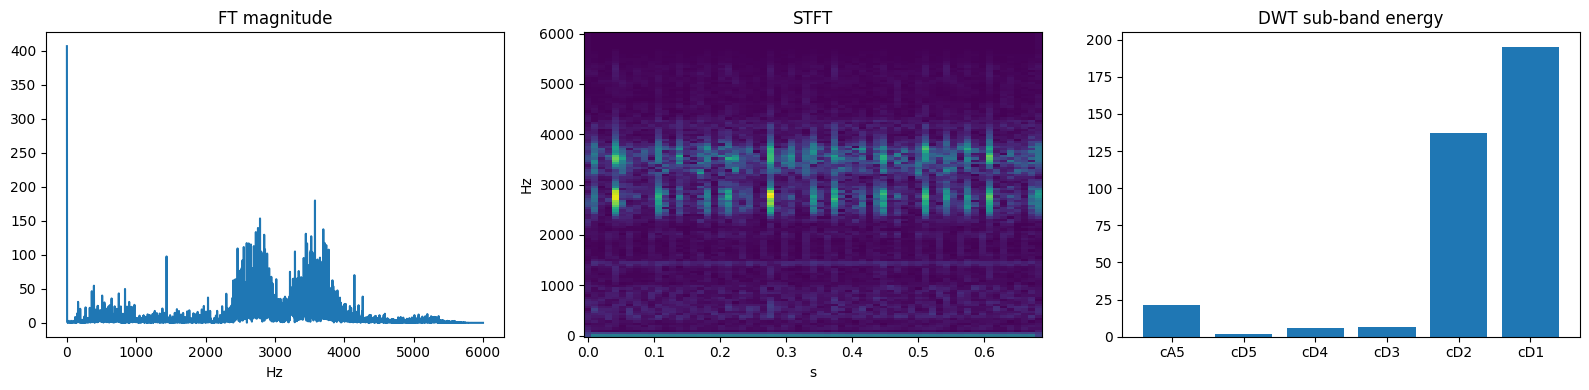

In [23]:
# ---- FT vs STFT vs DWT demo ----
sig = load_de(FILES["IR_014"][0])[:WIN * 4]
f_, t_, Z = stft(sig, fs=FS, nperseg=256)
c = pywt.wavedec(sig, WAVELET, level=LEVEL)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
fr = np.fft.rfftfreq(len(sig), 1 / FS)
ax[0].plot(fr, np.abs(np.fft.rfft(sig))); ax[0].set_title("FT magnitude"); ax[0].set_xlabel("Hz")
ax[1].pcolormesh(t_, f_, np.abs(Z), shading="auto"); ax[1].set_title("STFT")
ax[1].set_xlabel("s"); ax[1].set_ylabel("Hz")
ax[2].bar(bands, [np.sum(ci ** 2) for ci in c]); ax[2].set_title("DWT sub-band energy")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_ft_stft_dwt_demo.png", dpi=300); plt.show()

In [24]:
# ---- Summary sheet ----
sheet = []; S = sheet.append
S("=" * 70); S("REPORT FILL SHEET"); S("=" * 70)
S(f"Abstract : best model {fill['best_model']} accuracy {100*fill['best_acc']:.1f}% "
  f"macro F1 {fill['best_f1']:.3f} vs time-domain only {100*fill['time_only_acc']:.1f}%")
S(f"Table 2 : total {fill['total_windows']} | train {fill['train_windows']} | test {fill['test_windows']}")
S("Table 3 :")
for r in rows:
    S(f"  {r[0]:13s} {r[1]:22s} acc {100*r[2]:.1f}% F1 {r[3]:.3f}")
S("LOLO : " + "; ".join(f"{k} {100*v[0]:.1f} +/- {100*v[1]:.1f}%" for k, v in fill["lolo"].items()))
S("Table 4 : strongest " + ", ".join(strong)); S("          weakest " + ", ".join(weak))
S("Table 5 :")
for r in abl:
    S(f"  {r[0]:5s} wavelet {100*r[1]:.1f}% time+wavelet {100*r[2]:.1f}%")
top_bands = sorted(band_imp, key=band_imp.get, reverse=True)[:3]
S(f"Discussion: wavelet {100*fill['best_acc']:.1f}% vs time-domain {100*fill['time_only_acc']:.1f}%; "
  f"top sub-bands {top_bands}; random split {100*rand_acc:.1f}% vs cross-load "
  f"{100*res['RandomForest'][0]:.1f}% (RF) -> drop of {100*(rand_acc-res['RandomForest'][0]):.1f} pts")
S(f"Total run time: {time.time() - t_start:.0f}s")
text = "\n".join(sheet)
print(text)
open(f"{OUT_DIR}/FILL_SHEET.txt", "w").write(text)

REPORT FILL SHEET
Abstract : best model RandomForest accuracy 99.1% macro F1 0.991 vs time-domain only 96.7%
Table 2 : total 4643 | train 3465 | test 1178
Table 3 :
  RandomForest  Wavelet (37)           acc 99.1% F1 0.991
  XGBoost       Wavelet (37)           acc 97.9% F1 0.979
  SVM-RBF       Wavelet (37)           acc 99.1% F1 0.991
  RandomForest  Time-domain only (8)   acc 96.7% F1 0.967
LOLO : RandomForest 97.9 +/- 2.5%; XGBoost 95.9 +/- 4.8%; SVM-RBF 94.0 +/- 6.0%
Table 4 : strongest OR_021 (1.000), OR_007 (1.000), Normal (1.000)
          weakest OR_014 (0.956), Ball_014 (0.975), Ball_021 (0.979)
Table 5 :
  haar  wavelet 96.9% time+wavelet 95.3%
  db2   wavelet 98.4% time+wavelet 98.3%
  db4   wavelet 99.1% time+wavelet 98.6%
  db8   wavelet 99.8% time+wavelet 99.2%
Discussion: wavelet 99.1% vs time-domain 96.7%; top sub-bands ['cD2', 'cD1', 'cD4']; random split 99.4% vs cross-load 99.1% (RF) -> drop of 0.4 pts
Total run time: 339s


1097

In [25]:
# ---- (Optional) download all results as a zip ----
import shutil
shutil.make_archive("results", "zip", OUT_DIR)
try:
    from google.colab import files
    files.download("results.zip")
except Exception as e:
    print("Zip saved as results.zip (download from the file panel).", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>